# Phase 2 — Common Voice Communication Feature Extraction

This notebook creates a **real speech feature bank** for the interview-communication project.

It extracts:
- speech duration and speech/silence ratio
- words per minute (WPM)
- pauses/gaps
- filler words
- pitch
- RMS energy
- spectral features
- 13 MFCC means + standard deviations
- lightweight linguistic features

**Important:** Common Voice is used for feature extraction. This notebook does **not** invent communication labels and does **not** train a fake communication-quality model.

**Hardware target:** Intel i7-1360P, 16 GB RAM, Intel Iris Xe, CPU-only.

**Initial target:** 10,000 recordings. Checkpoints are saved every 500 successful recordings so the run can resume after interruption.


In [11]:
# Install once if needed
%pip install -q kagglehub pandas numpy librosa soundfile scikit-learn matplotlib tqdm pyarrow joblib


Note: you may need to restart the kernel to use updated packages.


In [12]:
# Imports and configuration
import os, re, gc, json, time, warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import joblib

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
MAX_SAMPLES = 10_000
CHECKPOINT_SIZE = 500

TARGET_SR = 16_000
N_MFCC = 13
N_FFT = 1024
HOP_LENGTH = 256

LONG_PAUSE_THRESHOLD = 1.0
SILENCE_TOP_DB = 35

RUN_WHISPER_VALIDATION = False
WHISPER_VALIDATION_SAMPLES = 100

np.random.seed(RANDOM_SEED)

DATA_DIR = Path("data")
CHECKPOINT_DIR = Path("checkpoints")
REPORT_DIR = Path("reports")
PLOT_DIR = Path("plots")
MODEL_DIR = Path("models")

for d in [DATA_DIR, CHECKPOINT_DIR, REPORT_DIR, PLOT_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("MAX_SAMPLES =", MAX_SAMPLES)
print("CHECKPOINT_SIZE =", CHECKPOINT_SIZE)
print("CPU-only pipeline enabled")


MAX_SAMPLES = 10000
CHECKPOINT_SIZE = 500
CPU-only pipeline enabled


In [13]:
# Download / locate the Kaggle dataset

import kagglehub

dataset_path = kagglehub.dataset_download(
    "vedant2022/common-voice-dataset-version-4"
)

DATASET_ROOT = Path(dataset_path)

print("Dataset root:", DATASET_ROOT)
for p in sorted(DATASET_ROOT.iterdir()):
    print(" -", p.name)


Resuming download from 12608077824 bytes (12336389815 bytes left)...
Resuming download to C:\Users\Mounindra\.cache\kagglehub\datasets\vedant2022\common-voice-dataset-version-4\1.archive (12608077824/24944467639) bytes left.


100%|██████████| 23.2G/23.2G [23:22<00:00, 8.80MB/s]  

Extracting files...


Dataset root: C:\Users\Mounindra\.cache\kagglehub\datasets\vedant2022\common-voice-dataset-version-4\versions\1
 - data-file
 - new-clip


In [14]:
# Discover metadata and audio files without assuming filenames

def discover_files(root):
    tables = list(root.rglob("*.csv")) + list(root.rglob("*.tsv"))
    audio = []
    for pattern in ["*.wav", "*.mp3", "*.flac", "*.ogg", "*.m4a"]:
        audio.extend(root.rglob(pattern))
    return sorted(tables), sorted(audio)

table_files, audio_files = discover_files(DATASET_ROOT)

print(f"Table files: {len(table_files):,}")
for p in table_files[:20]:
    print(" ", p.relative_to(DATASET_ROOT))

print(f"Audio files discovered: {len(audio_files):,}")
for p in audio_files[:10]:
    print(" ", p.relative_to(DATASET_ROOT))


Table files: 6
  data-file\dev.tsv
  data-file\invalidated.tsv
  data-file\other.tsv
  data-file\test.tsv
  data-file\train.tsv
  data-file\validated.tsv
Audio files discovered: 692,715
  new-clip\common_voice_en_100034.mp3
  new-clip\common_voice_en_100035.mp3
  new-clip\common_voice_en_100036.mp3
  new-clip\common_voice_en_100037.mp3
  new-clip\common_voice_en_100038.mp3
  new-clip\common_voice_en_100039.mp3
  new-clip\common_voice_en_100040.mp3
  new-clip\common_voice_en_100041.mp3
  new-clip\common_voice_en_100042.mp3
  new-clip\common_voice_en_100043.mp3


In [15]:
# Identify and load the most likely Common Voice metadata table

def read_preview(path):
    try:
        sep = "\t" if path.suffix.lower() == ".tsv" else ","
        return pd.read_csv(path, sep=sep, nrows=5, low_memory=False)
    except Exception:
        return None

def column_score(columns):
    cols = {str(c).lower() for c in columns}
    return sum(x in cols for x in [
        "path", "sentence", "client_id", "clientid", "text",
        "audio", "locale", "language"
    ])

candidates = []
for p in table_files:
    preview = read_preview(p)
    if preview is not None:
        candidates.append((column_score(preview.columns), p, list(preview.columns)))

candidates.sort(reverse=True, key=lambda x: x[0])

if not candidates:
    raise RuntimeError("No readable CSV/TSV metadata file was found.")

for score, p, cols in candidates[:10]:
    print(f"Score={score}: {p.relative_to(DATASET_ROOT)}")
    print("  ", cols[:25])

METADATA_PATH = candidates[0][1]
sep = "\t" if METADATA_PATH.suffix.lower() == ".tsv" else ","
meta = pd.read_csv(METADATA_PATH, sep=sep, low_memory=False)

print("\nSelected:", METADATA_PATH)
print("Shape:", meta.shape)
print("Columns:", meta.columns.tolist())
display(meta.head())


Score=3: data-file\dev.tsv
   ['client_id', 'path', 'sentence', 'up_votes', 'down_votes', 'age', 'gender', 'accent']
Score=3: data-file\invalidated.tsv
   ['client_id', 'path', 'sentence', 'up_votes', 'down_votes', 'age', 'gender', 'accent']
Score=3: data-file\other.tsv
   ['client_id', 'path', 'sentence', 'up_votes', 'down_votes', 'age', 'gender', 'accent']
Score=3: data-file\test.tsv
   ['client_id', 'path', 'sentence', 'up_votes', 'down_votes', 'age', 'gender', 'accent']
Score=3: data-file\train.tsv
   ['client_id', 'path', 'sentence', 'up_votes', 'down_votes', 'age', 'gender', 'accent']
Score=3: data-file\validated.tsv
   ['client_id', 'path', 'sentence', 'up_votes', 'down_votes', 'age', 'gender', 'accent']

Selected: C:\Users\Mounindra\.cache\kagglehub\datasets\vedant2022\common-voice-dataset-version-4\versions\1\data-file\dev.tsv
Shape: (15531, 8)
Columns: ['client_id', 'path', 'sentence', 'up_votes', 'down_votes', 'age', 'gender', 'accent']


,client_id,path,sentence,up_votes,down_votes,age,gender,accent
0,d277a1f3904ae00b09b73122b87674e7c2c78e08120721...,common_voice_en_18540003.mp3,"When water is scarce, avoid wasting it.",2,0,NaN,NaN,NaN
1,d277a1f3904ae00b09b73122b87674e7c2c78e08120721...,common_voice_en_18540005.mp3,You will drive with her to her door.,2,1,NaN,NaN,NaN
2,d277a1f3904ae00b09b73122b87674e7c2c78e08120721...,common_voice_en_18540006.mp3,"Celia shrank back, shivering.",2,1,NaN,NaN,NaN
3,d28566a5d710dbd7e6c2ab4686ad5bd22ec86588a3abd1...,common_voice_en_65557.mp3,Have you got a ring?,2,0,thirties,male,indian
4,d28566a5d710dbd7e6c2ab4686ad5bd22ec86588a3abd1...,common_voice_en_65559.mp3,I didn't even ask him.,2,0,thirties,male,indian


In [16]:
# Detect important columns

def find_col(columns, names):
    lookup = {str(c).lower(): c for c in columns}
    for n in names:
        if n.lower() in lookup:
            return lookup[n.lower()]
    return None

PATH_COL = find_col(meta.columns, ["path", "filename", "file", "audio"])
TEXT_COL = find_col(meta.columns, ["sentence", "text", "transcript", "transcription"])
SPEAKER_COL = find_col(meta.columns, ["client_id", "clientid", "speaker_id", "speaker"])
LANG_COL = find_col(meta.columns, ["locale", "language", "lang"])
AGE_COL = find_col(meta.columns, ["age"])
GENDER_COL = find_col(meta.columns, ["gender", "sex"])

print("PATH_COL    =", PATH_COL)
print("TEXT_COL    =", TEXT_COL)
print("SPEAKER_COL =", SPEAKER_COL)
print("LANG_COL    =", LANG_COL)
print("AGE_COL     =", AGE_COL)
print("GENDER_COL  =", GENDER_COL)

if PATH_COL is None:
    raise RuntimeError("Could not identify the audio path column.")


PATH_COL    = path
TEXT_COL    = sentence
SPEAKER_COL = client_id
LANG_COL    = None
AGE_COL     = age
GENDER_COL  = gender


In [17]:
# Resolve audio paths

audio_lookup = {p.name: p for p in audio_files}

def resolve_audio_path(value):
    if pd.isna(value):
        return None
    value = str(value).replace("\\", "/")
    direct = DATASET_ROOT / value
    if direct.exists():
        return direct
    return audio_lookup.get(Path(value).name)

meta["_audio_path"] = meta[PATH_COL].map(resolve_audio_path)
usable = meta[meta["_audio_path"].notna()].copy()

print("Metadata rows:", f"{len(meta):,}")
print("Rows with audio:", f"{len(usable):,}")
print("Unresolved:", f"{len(meta)-len(usable):,}")


Metadata rows: 15,531
Rows with audio: 3,492
Unresolved: 12,039


In [18]:
# Reproducible speaker-aware subset

if SPEAKER_COL is not None:
    shuffled = usable.sample(frac=1, random_state=RANDOM_SEED)
    first_per_speaker = shuffled.drop_duplicates(SPEAKER_COL)

    if len(first_per_speaker) >= MAX_SAMPLES:
        selected = first_per_speaker.sample(MAX_SAMPLES, random_state=RANDOM_SEED)
    else:
        remaining = shuffled.loc[~shuffled.index.isin(first_per_speaker.index)]
        needed = MAX_SAMPLES - len(first_per_speaker)
        extra = remaining.sample(min(needed, len(remaining)), random_state=RANDOM_SEED)
        selected = pd.concat([first_per_speaker, extra])

    selected = selected.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)
else:
    selected = usable.sample(min(MAX_SAMPLES, len(usable)), random_state=RANDOM_SEED).reset_index(drop=True)

selected["_record_id"] = selected.index.astype(str)

print("Selected recordings:", f"{len(selected):,}")
if SPEAKER_COL is not None:
    print("Selected speakers:", f"{selected[SPEAKER_COL].nunique():,}")
    print(selected[SPEAKER_COL].value_counts().describe())

selected.to_csv(DATA_DIR / f"selected_common_voice_{len(selected)}.csv", index=False)


Selected recordings: 3,492
Selected speakers: 954
count    954.000000
mean       3.660377
std        1.212891
min        1.000000
25%        3.000000
50%        4.000000
75%        4.000000
max        5.000000
Name: count, dtype: float64


In [19]:
# Save experiment configuration

config = {
    "random_seed": RANDOM_SEED,
    "max_samples": MAX_SAMPLES,
    "checkpoint_size": CHECKPOINT_SIZE,
    "target_sr": TARGET_SR,
    "n_mfcc": N_MFCC,
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH,
    "long_pause_threshold": LONG_PAUSE_THRESHOLD,
    "silence_top_db": SILENCE_TOP_DB,
    "dataset_path": str(DATASET_ROOT),
    "metadata_path": str(METADATA_PATH),
    "created_at": datetime.now().isoformat()
}

with open(DATA_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Configuration saved.")


Configuration saved.


In [20]:
# Checkpoint utilities

def checkpoint_files():
    return sorted(CHECKPOINT_DIR.glob("batch_*.parquet"))

def load_processed_ids():
    ids = set()
    for cp in checkpoint_files():
        try:
            ids.update(pd.read_parquet(cp, columns=["_record_id"])["_record_id"].astype(str))
        except Exception as e:
            print("Warning:", cp.name, e)
    return ids

processed_ids = load_processed_ids()
print("Existing checkpoint batches:", len(checkpoint_files()))
print("Previously processed:", f"{len(processed_ids):,}")
print("Resuming..." if processed_ids else "Starting fresh.")


Existing checkpoint batches: 0
Previously processed: 0
Starting fresh.


In [21]:
# Text / filler feature helpers

STRICT_FILLERS = {"uh", "um", "uhm", "er", "erm"}
DISCOURSE_FILLERS = {"like", "you", "know"}

def normalize_text(text):
    if text is None or pd.isna(text):
        return ""
    return re.sub(r"\s+", " ", str(text).lower().strip())

def tokenize_words(text):
    return re.findall(r"[a-zA-Z]+(?:'[a-zA-Z]+)?", text.lower())

def linguistic_features(text):
    text = normalize_text(text)
    words = tokenize_words(text)
    n = len(words)
    unique = len(set(words))
    sentence_count = max(1, len(re.findall(r"[.!?]+", text))) if text else 0

    return {
        "word_count": n,
        "character_count": len(re.sub(r"\s+", "", text)),
        "unique_word_count": unique,
        "average_word_length": float(np.mean([len(w) for w in words])) if words else 0.0,
        "type_token_ratio": unique / n if n else 0.0,
        "sentence_count": sentence_count,
        "average_words_per_sentence": n / sentence_count if sentence_count else 0.0,
    }

def filler_features(text):
    words = tokenize_words(text)
    strict = sum(w in STRICT_FILLERS for w in words)

    # Conservative handling of "like" and "you know":
    # "you know" is counted as a phrase, not separate words.
    you_know = len(re.findall(r"\byou\s+know\b", normalize_text(text)))
    like_count = sum(w == "like" for w in words)

    discourse = you_know + like_count
    total = strict + discourse
    n = len(words)

    return {
        "strict_filler_count": strict,
        "conversational_filler_count": discourse,
        "total_filler_count": total,
        "fillers_per_100_words": 100 * total / n if n else 0.0,
        "strict_fillers_per_100_words": 100 * strict / n if n else 0.0,
    }


In [22]:
# Audio feature helpers

def safe_stats(x, prefix):
    x = np.asarray(x, dtype=np.float32)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return {f"{prefix}_{s}": np.nan for s in ["mean","std","min","max","range"]}
    return {
        f"{prefix}_mean": float(np.mean(x)),
        f"{prefix}_std": float(np.std(x)),
        f"{prefix}_min": float(np.min(x)),
        f"{prefix}_max": float(np.max(x)),
        f"{prefix}_range": float(np.max(x) - np.min(x)),
    }

def pause_features(y, sr):
    total = len(y) / sr
    intervals = librosa.effects.split(
        y, top_db=SILENCE_TOP_DB,
        frame_length=N_FFT, hop_length=HOP_LENGTH
    )

    if len(intervals) == 0:
        return {
            "speech_duration_seconds": 0.0,
            "silence_duration_seconds": total,
            "speech_ratio": 0.0,
            "silence_ratio": 1.0,
            "pause_count": 0,
            "total_pause_duration": total,
            "mean_pause_duration": np.nan,
            "median_pause_duration": np.nan,
            "std_pause_duration": np.nan,
            "minimum_pause_duration": np.nan,
            "maximum_pause_duration": np.nan,
            "pause_ratio": 1.0,
            "pauses_per_minute": 0.0,
            "long_pause_count": 0,
            "long_pause_ratio": 0.0,
        }

    speech = float(np.sum(intervals[:,1] - intervals[:,0]) / sr)
    silence = max(0.0, total - speech)

    pauses = np.array([
        (intervals[i,0] - intervals[i-1,1]) / sr
        for i in range(1, len(intervals))
        if intervals[i,0] > intervals[i-1,1]
    ], dtype=np.float32)

    long_count = int(np.sum(pauses >= LONG_PAUSE_THRESHOLD)) if len(pauses) else 0

    return {
        "speech_duration_seconds": speech,
        "silence_duration_seconds": silence,
        "speech_ratio": speech / total if total else 0.0,
        "silence_ratio": silence / total if total else 0.0,
        "pause_count": int(len(pauses)),
        "total_pause_duration": float(np.sum(pauses)) if len(pauses) else 0.0,
        "mean_pause_duration": float(np.mean(pauses)) if len(pauses) else np.nan,
        "median_pause_duration": float(np.median(pauses)) if len(pauses) else np.nan,
        "std_pause_duration": float(np.std(pauses)) if len(pauses) else np.nan,
        "minimum_pause_duration": float(np.min(pauses)) if len(pauses) else np.nan,
        "maximum_pause_duration": float(np.max(pauses)) if len(pauses) else np.nan,
        "pause_ratio": float(np.sum(pauses) / total) if total else 0.0,
        "pauses_per_minute": float(len(pauses) / total * 60) if total else 0.0,
        "long_pause_count": long_count,
        "long_pause_ratio": float(long_count / len(pauses)) if len(pauses) else 0.0,
    }

def pitch_features(y, sr):
    try:
        f0, _, _ = librosa.pyin(
            y, fmin=librosa.note_to_hz("C2"),
            fmax=librosa.note_to_hz("C7"),
            sr=sr, frame_length=2048, hop_length=HOP_LENGTH
        )
        valid = f0[np.isfinite(f0)]
        return {
            "pitch_mean": float(np.mean(valid)) if len(valid) else np.nan,
            "pitch_median": float(np.median(valid)) if len(valid) else np.nan,
            "pitch_std": float(np.std(valid)) if len(valid) else np.nan,
            "pitch_min": float(np.min(valid)) if len(valid) else np.nan,
            "pitch_max": float(np.max(valid)) if len(valid) else np.nan,
            "pitch_range": float(np.max(valid)-np.min(valid)) if len(valid) else np.nan,
            "voiced_frame_ratio": float(np.mean(np.isfinite(f0))),
        }
    except Exception:
        return {k: np.nan for k in [
            "pitch_mean","pitch_median","pitch_std","pitch_min",
            "pitch_max","pitch_range","voiced_frame_ratio"
        ]}

def spectral_mfcc_features(y, sr):
    S = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH))
    centroid = librosa.feature.spectral_centroid(S=S, sr=sr).flatten()
    bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr).flatten()
    rolloff = librosa.feature.spectral_rolloff(S=S, sr=sr).flatten()
    zcr = librosa.feature.zero_crossing_rate(y, frame_length=N_FFT, hop_length=HOP_LENGTH).flatten()

    mfcc = librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=N_MFCC,
        n_fft=N_FFT, hop_length=HOP_LENGTH
    )

    out = {}
    out.update(safe_stats(centroid, "spectral_centroid"))
    out.update(safe_stats(bandwidth, "spectral_bandwidth"))
    out.update(safe_stats(rolloff, "spectral_rolloff"))
    out.update(safe_stats(zcr, "zero_crossing_rate"))

    for i in range(N_MFCC):
        v = mfcc[i]
        out[f"mfcc_{i+1:02d}_mean"] = float(np.mean(v))
        out[f"mfcc_{i+1:02d}_std"] = float(np.std(v))
    return out


In [23]:
# Per-recording extraction

def process_recording(row):
    path = Path(row["_audio_path"])
    y, sr = librosa.load(path, sr=TARGET_SR, mono=True)
    y = np.asarray(y, dtype=np.float32)

    if len(y) == 0:
        raise ValueError("Empty audio")

    total_duration = len(y) / sr
    text = normalize_text(row[TEXT_COL]) if TEXT_COL else ""

    pause = pause_features(y, sr)
    ling = linguistic_features(text)
    fill = filler_features(text)

    speech_duration = pause["speech_duration_seconds"]
    words = ling["word_count"]

    wpm = (words / speech_duration * 60.0) if speech_duration > 0 and words > 0 else np.nan
    wps = (words / speech_duration) if speech_duration > 0 and words > 0 else np.nan

    rms = librosa.feature.rms(
        y=y, frame_length=N_FFT, hop_length=HOP_LENGTH
    ).flatten()

    out = {
        "_record_id": str(row["_record_id"]),
        "filename": str(row[PATH_COL]),
        "audio_path": str(path),
        "transcript": text,
        "total_duration_seconds": float(total_duration),
        "sampling_rate": int(sr),
        "number_of_samples": int(len(y)),
        "wpm_speech_duration": float(wpm) if np.isfinite(wpm) else np.nan,
        "words_per_second": float(wps) if np.isfinite(wps) else np.nan,
    }

    out.update(safe_stats(rms, "rms"))
    out.update(pause)
    out.update(pitch_features(y, sr))
    out.update(spectral_mfcc_features(y, sr))
    out.update(ling)
    out.update(fill)

    for name, col in [
        ("speaker_id", SPEAKER_COL),
        ("language", LANG_COL),
        ("age", AGE_COL),
        ("gender", GENDER_COL),
    ]:
        if col is not None and col in row.index:
            value = row[col]
            out[name] = None if pd.isna(value) else value

    return out


In [24]:
# Resumable extraction loop
# Re-run this cell after an interruption: existing checkpoints are skipped.

processed_ids = load_processed_ids()
remaining = selected[~selected["_record_id"].astype(str).isin(processed_ids)].copy()

print("Selected:", f"{len(selected):,}")
print("Already processed:", f"{len(processed_ids):,}")
print("Remaining:", f"{len(remaining):,}")

failed_path = CHECKPOINT_DIR / "failed_files.csv"
if failed_path.exists():
    failed_df = pd.read_csv(failed_path)
else:
    failed_df = pd.DataFrame(columns=[
        "record_id", "filename", "error_type", "error_message", "timestamp"
    ])

batch_rows = []
run_start = time.time()
success_count = 0
failure_count = 0

for _, row in tqdm(remaining.iterrows(), total=len(remaining), desc="Extracting"):
    record_id = str(row["_record_id"])

    try:
        batch_rows.append(process_recording(row))
        success_count += 1

    except Exception as e:
        failure_count += 1
        failed_df.loc[len(failed_df)] = {
            "record_id": record_id,
            "filename": str(row.get(PATH_COL, "")),
            "error_type": type(e).__name__,
            "error_message": str(e)[:1000],
            "timestamp": datetime.now().isoformat()
        }
        failed_df.to_csv(failed_path, index=False)

    if len(batch_rows) >= CHECKPOINT_SIZE:
        batch_df = pd.DataFrame(batch_rows)
        batch_no = len(checkpoint_files())
        first_id = batch_df["_record_id"].iloc[0]
        last_id = batch_df["_record_id"].iloc[-1]
        cp = CHECKPOINT_DIR / f"batch_{batch_no:05d}_{first_id}_{last_id}.parquet"
        batch_df.to_parquet(cp, index=False)
        batch_rows = []
        gc.collect()

        elapsed = time.time() - run_start
        print(
            f"Checkpoint: {cp.name} | "
            f"success={success_count:,} | failed={failure_count:,} | "
            f"elapsed={elapsed/60:.1f} min"
        )

if batch_rows:
    batch_df = pd.DataFrame(batch_rows)
    batch_no = len(checkpoint_files())
    first_id = batch_df["_record_id"].iloc[0]
    last_id = batch_df["_record_id"].iloc[-1]
    cp = CHECKPOINT_DIR / f"batch_{batch_no:05d}_{first_id}_{last_id}.parquet"
    batch_df.to_parquet(cp, index=False)
    print("Final checkpoint:", cp.name)

failed_df.to_csv(failed_path, index=False)

progress = {
    "total_selected": len(selected),
    "previously_processed": len(processed_ids),
    "new_success": success_count,
    "new_failures": failure_count,
    "checkpoint_count": len(checkpoint_files()),
    "timestamp": datetime.now().isoformat()
}
with open(CHECKPOINT_DIR / "progress.json", "w", encoding="utf-8") as f:
    json.dump(progress, f, indent=2)

print("\nRun complete:", progress)


Selected: 3,492
Already processed: 0
Remaining: 3,492


Extracting:   0%|          | 0/3492 [00:00<?, ?it/s]

Checkpoint: batch_00000_0_499.parquet | success=500 | failed=0 | elapsed=28.0 min
Checkpoint: batch_00001_500_999.parquet | success=1,000 | failed=0 | elapsed=56.7 min
Checkpoint: batch_00002_1000_1499.parquet | success=1,500 | failed=0 | elapsed=84.1 min
Checkpoint: batch_00003_1500_1999.parquet | success=2,000 | failed=0 | elapsed=105.2 min
Checkpoint: batch_00004_2000_2499.parquet | success=2,500 | failed=0 | elapsed=123.9 min
Checkpoint: batch_00005_2500_2999.parquet | success=3,000 | failed=0 | elapsed=148.7 min
Final checkpoint: batch_00006_3000_3491.parquet

Run complete: {'total_selected': 3492, 'previously_processed': 0, 'new_success': 3492, 'new_failures': 0, 'checkpoint_count': 7, 'timestamp': '2026-08-19T19:56:01.135883'}


In [25]:
# Combine checkpoints into final feature dataset

cp_files = checkpoint_files()
if not cp_files:
    raise RuntimeError("No checkpoints found. Run the extraction cell first.")

features = pd.concat(
    [pd.read_parquet(p) for p in cp_files],
    ignore_index=True
)

features = features.drop_duplicates("_record_id", keep="last")

csv_output = DATA_DIR / f"communication_features_{len(features)}.csv"
parquet_output = DATA_DIR / f"communication_features_{len(features)}.parquet"

features.to_csv(csv_output, index=False)
features.to_parquet(parquet_output, index=False)

print("Shape:", features.shape)
print("CSV:", csv_output)
print("Parquet:", parquet_output)


Shape: (3492, 97)
CSV: data\communication_features_3492.csv
Parquet: data\communication_features_3492.parquet


In [26]:
# Quality control

numeric_cols = features.select_dtypes(include=[np.number]).columns

quality = []
for col in numeric_cols:
    s = pd.to_numeric(features[col], errors="coerce")
    quality.append({
        "feature": col,
        "missing_count": int(s.isna().sum()),
        "missing_percent": float(s.isna().mean()*100),
        "infinite_count": int(np.isinf(s).sum()),
        "min": float(s.min()) if s.notna().any() else np.nan,
        "max": float(s.max()) if s.notna().any() else np.nan,
        "mean": float(s.mean()) if s.notna().any() else np.nan,
        "median": float(s.median()) if s.notna().any() else np.nan,
    })

quality = pd.DataFrame(quality)
quality.to_csv(REPORT_DIR / "data_quality_report.csv", index=False)

print("Rows:", len(features))
print("Columns:", len(features.columns))
print("Duplicate IDs:", features["_record_id"].duplicated().sum())

print("\nWPM outliers flagged for inspection (not deleted):")
display(features.loc[
    (features["wpm_speech_duration"] < 20) |
    (features["wpm_speech_duration"] > 300),
    ["filename", "wpm_speech_duration", "word_count", "speech_duration_seconds"]
].head(20))


Rows: 3492
Columns: 97
Duplicate IDs: 0

WPM outliers flagged for inspection (not deleted):


,filename,wpm_speech_duration,word_count,speech_duration_seconds
121,common_voice_en_18508707.mp3,312.500000,4,0.768
1417,common_voice_en_18419398.mp3,349.576271,11,1.888
1856,common_voice_en_17781157.mp3,319.148936,8,1.504
2039,common_voice_en_17748768.mp3,308.219178,6,1.168
2374,common_voice_en_19219256.mp3,535.714286,9,1.008
3120,common_voice_en_18552482.mp3,328.947368,5,0.912
3392,common_voice_en_19239163.mp3,323.275862,5,0.928


In [27]:
# Feature documentation

metadata_cols = {
    "_record_id","filename","audio_path","transcript",
    "speaker_id","language","age","gender"
}

def group_for(col):
    if col in metadata_cols: return "metadata"
    if col.startswith("mfcc_"): return "MFCC"
    if col.startswith("pitch") or col == "voiced_frame_ratio": return "pitch"
    if col.startswith("spectral"): return "spectral"
    if col.startswith("rms"): return "energy"
    if "pause" in col or "silence" in col or "speech_" in col: return "speech_activity_pause"
    if "filler" in col: return "fillers"
    if col in {"word_count","character_count","unique_word_count","average_word_length",
               "type_token_ratio","sentence_count","average_words_per_sentence"}: return "linguistic"
    if "wpm" in col or "words_per_second" in col: return "speech_rate"
    return "other"

feature_description = pd.DataFrame([
    {
        "feature_name": col,
        "feature_group": group_for(col),
        "description": "Extracted feature; see notebook function for exact calculation.",
        "unit": "varies",
    }
    for col in features.columns
])

feature_description.to_csv(DATA_DIR / "feature_description.csv", index=False)

with open(DATA_DIR / "feature_columns.json", "w", encoding="utf-8") as f:
    json.dump(features.columns.tolist(), f, indent=2)

print("Feature schema saved.")


Feature schema saved.


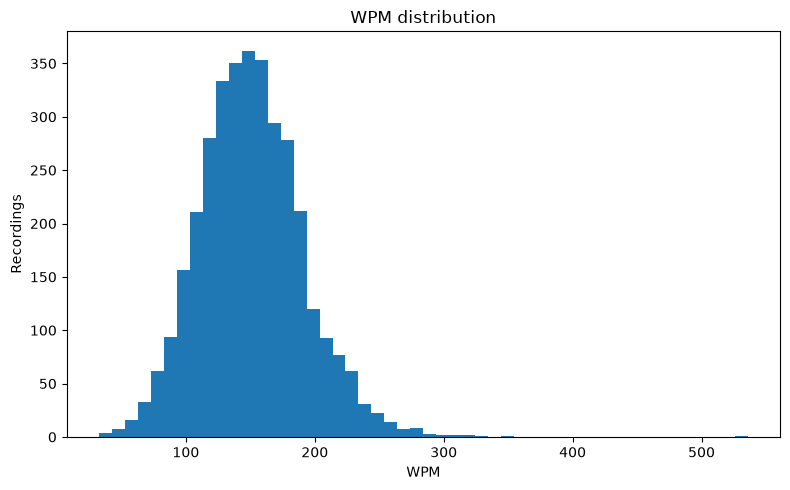

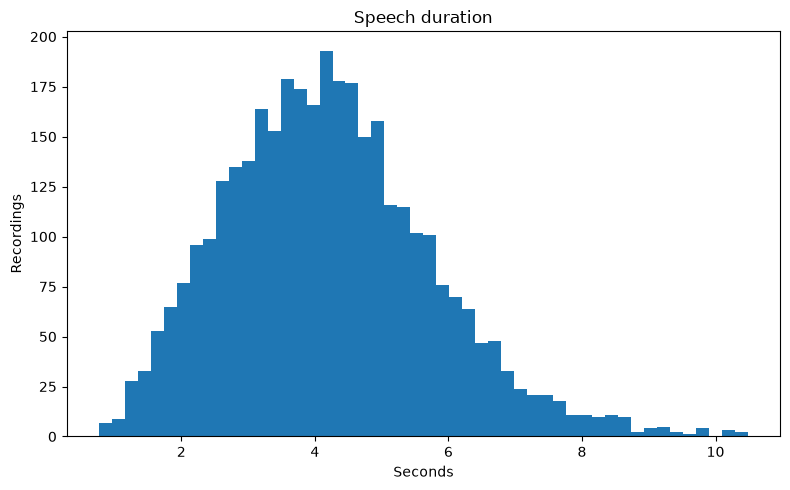

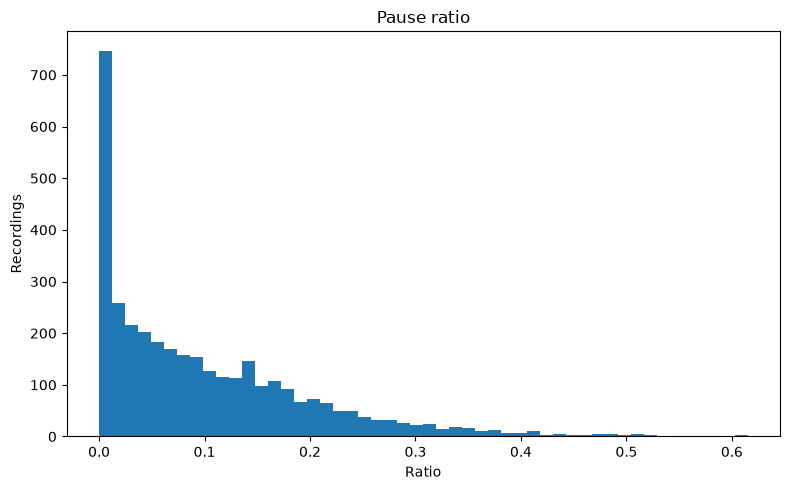

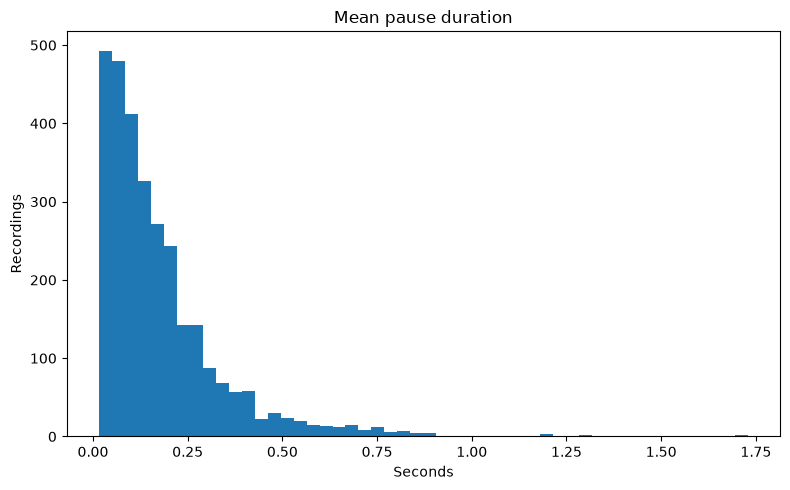

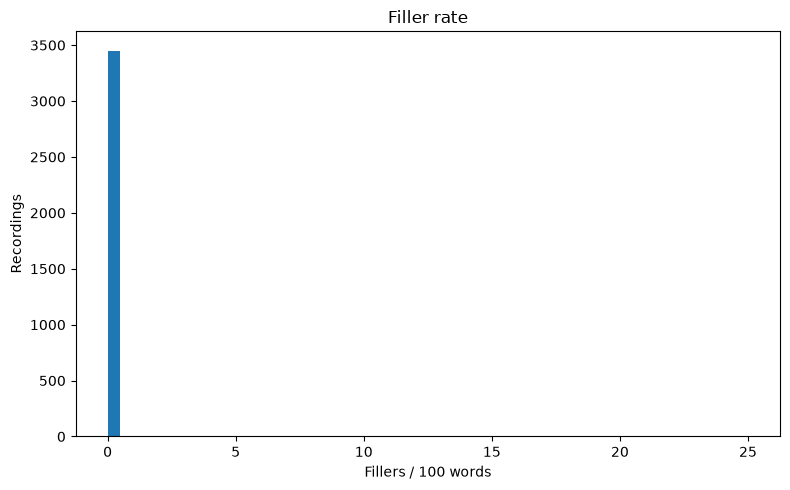

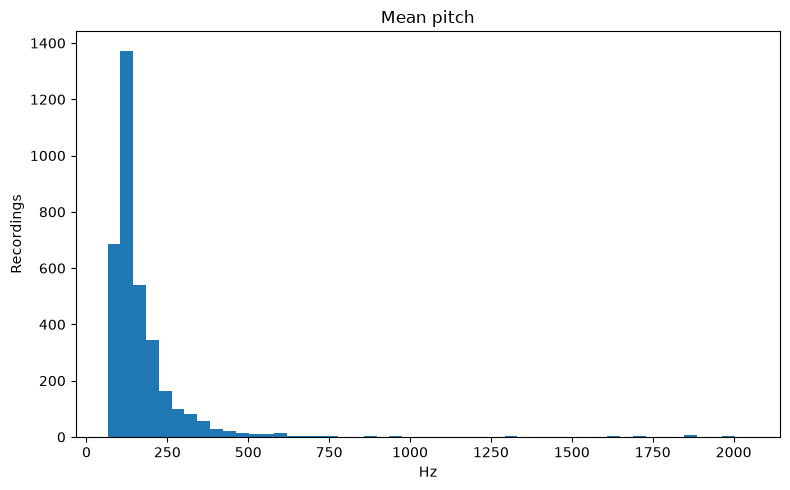

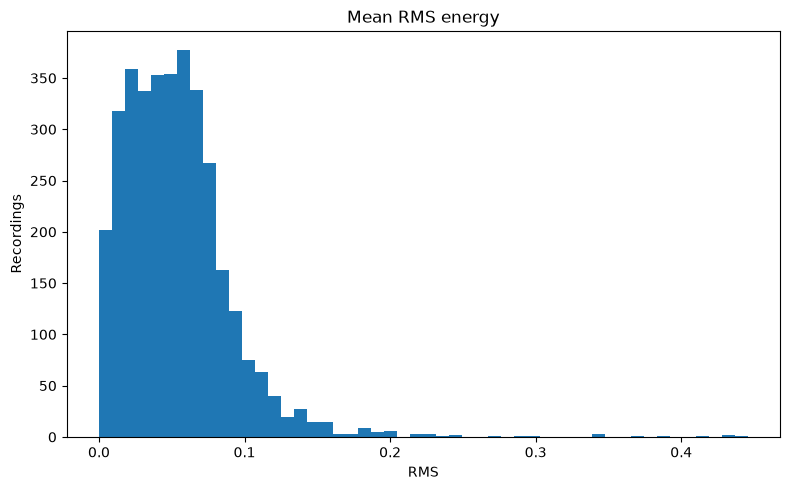

In [28]:
# Exploratory plots

plot_specs = [
    ("wpm_speech_duration", "WPM distribution", "WPM"),
    ("speech_duration_seconds", "Speech duration", "Seconds"),
    ("pause_ratio", "Pause ratio", "Ratio"),
    ("mean_pause_duration", "Mean pause duration", "Seconds"),
    ("fillers_per_100_words", "Filler rate", "Fillers / 100 words"),
    ("pitch_mean", "Mean pitch", "Hz"),
    ("rms_mean", "Mean RMS energy", "RMS"),
]

for col, title, xlabel in plot_specs:
    if col not in features.columns:
        continue
    v = pd.to_numeric(features[col], errors="coerce").replace([np.inf,-np.inf],np.nan).dropna()
    if len(v) == 0:
        continue
    plt.figure(figsize=(8,5))
    plt.hist(v, bins=50)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Recordings")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{col}.png", dpi=150)
    plt.show()


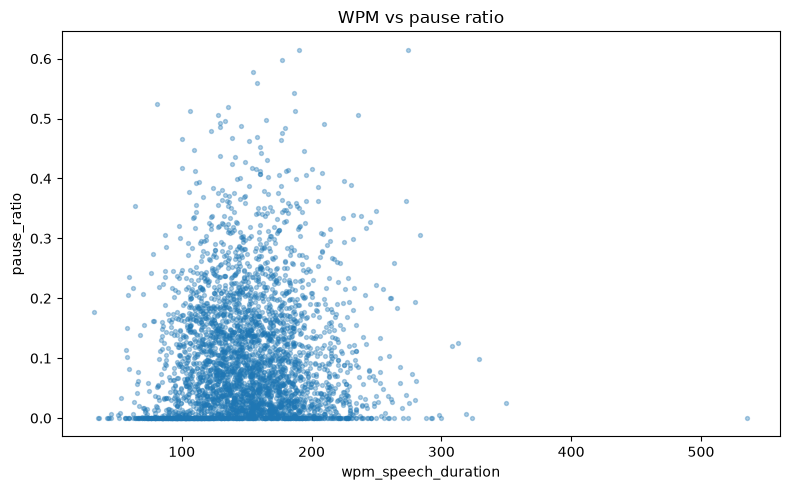

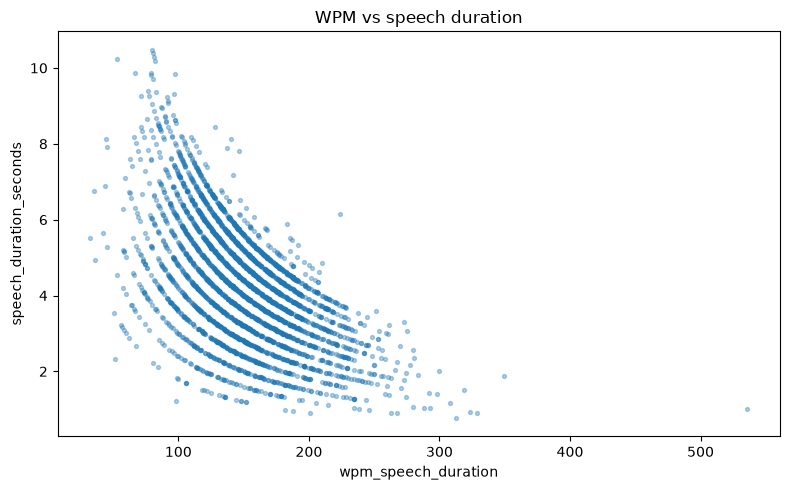

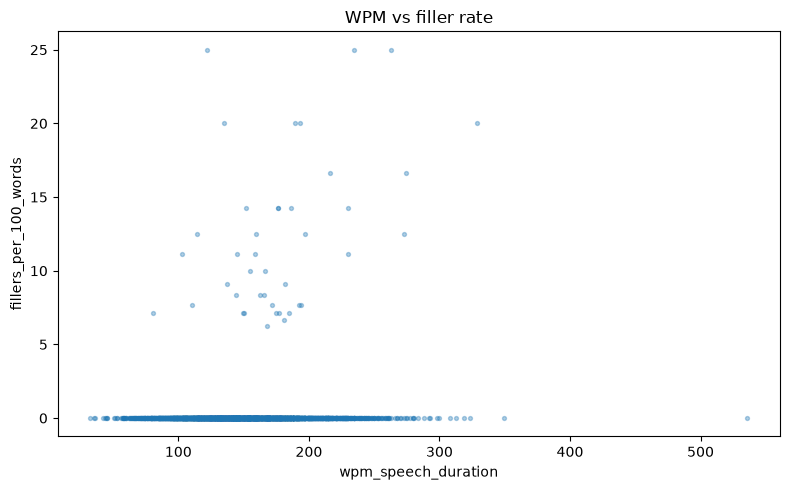

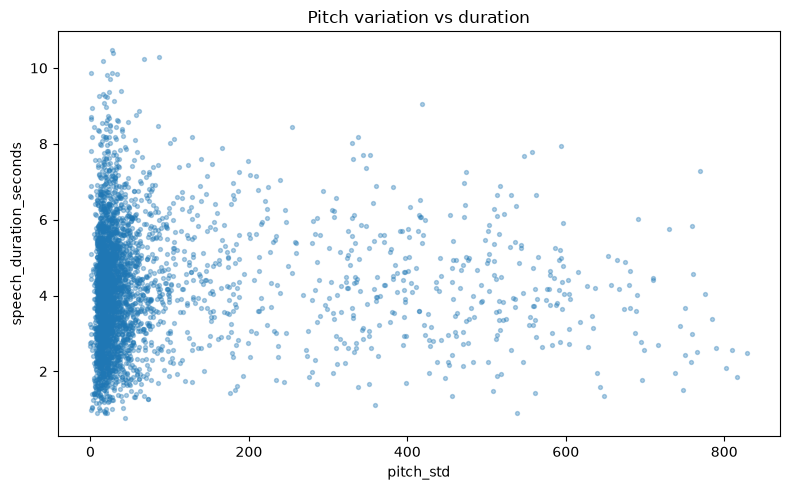

In [29]:
# Relationship plots

for x, y, title, filename in [
    ("wpm_speech_duration","pause_ratio","WPM vs pause ratio","wpm_vs_pause.png"),
    ("wpm_speech_duration","speech_duration_seconds","WPM vs speech duration","wpm_vs_duration.png"),
    ("wpm_speech_duration","fillers_per_100_words","WPM vs filler rate","wpm_vs_fillers.png"),
    ("pitch_std","speech_duration_seconds","Pitch variation vs duration","pitch_vs_duration.png"),
]:
    if x not in features or y not in features:
        continue
    tmp = features[[x,y]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(tmp) < 2:
        continue
    plt.figure(figsize=(8,5))
    plt.scatter(tmp[x], tmp[y], s=8, alpha=0.35)
    plt.title(title)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / filename, dpi=150)
    plt.show()


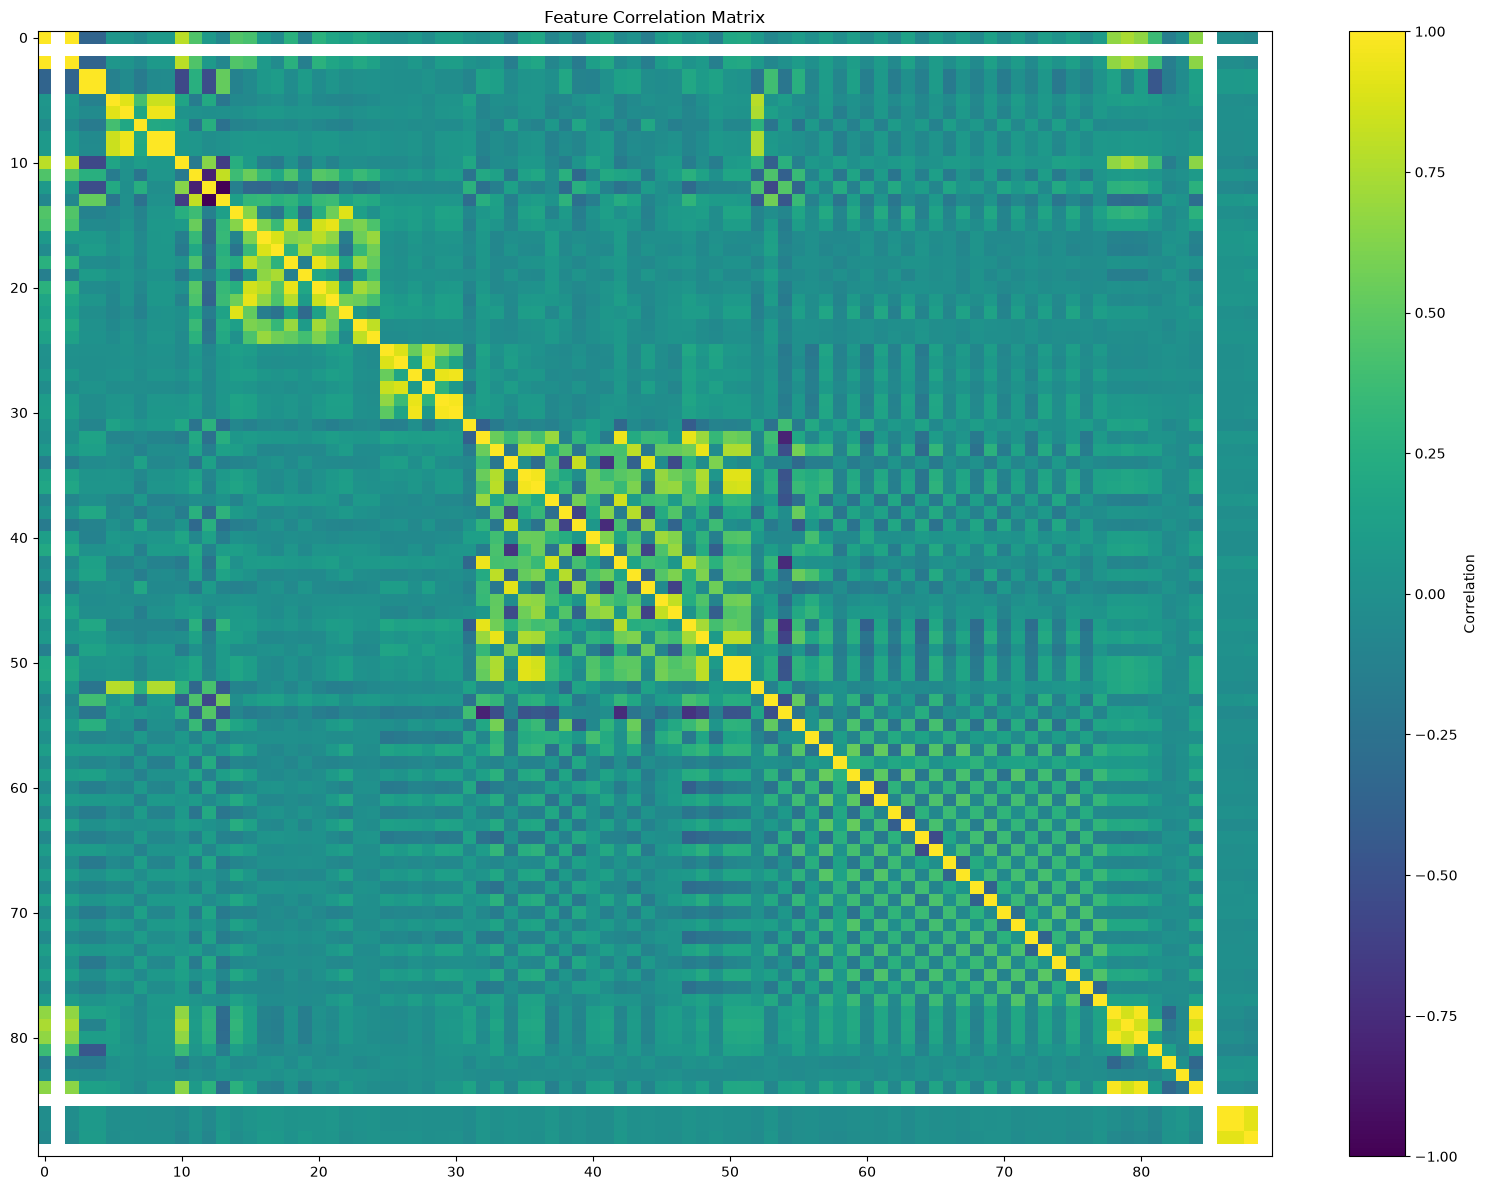

In [30]:
# Correlation analysis

numeric = features.select_dtypes(include=[np.number]).drop(
    columns=["_record_id"], errors="ignore"
)

corr = numeric.corr()
corr.to_csv(REPORT_DIR / "feature_correlation_matrix.csv")

plt.figure(figsize=(16,12))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(PLOT_DIR / "feature_correlation_matrix.png", dpi=150)
plt.show()


Components for 90% variance: 31
Components for 95% variance: 40
Components for 99% variance: 55


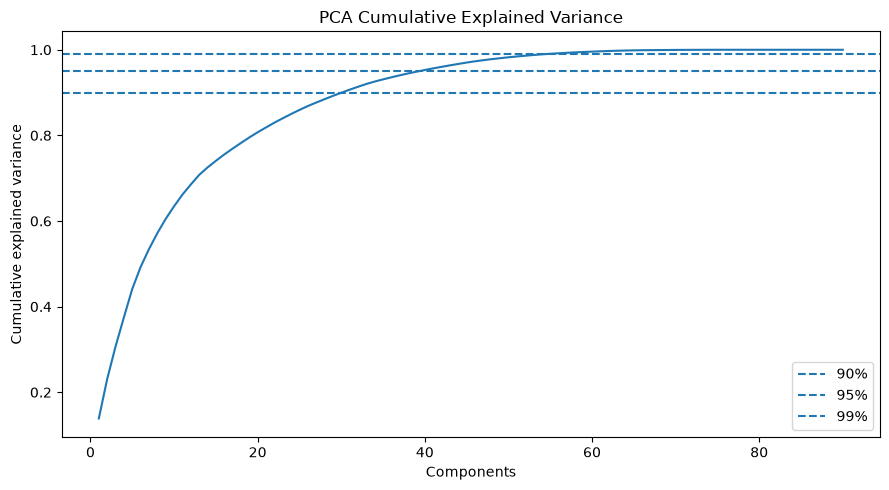

['models\\communication_feature_pca.pkl']

In [31]:
# PCA — exploratory dimensionality analysis only

X = features.select_dtypes(include=[np.number]).drop(
    columns=["_record_id"], errors="ignore"
).replace([np.inf,-np.inf],np.nan)

X = X.fillna(X.median(numeric_only=True))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(random_state=RANDOM_SEED)
pca.fit(X_scaled)

cum = np.cumsum(pca.explained_variance_ratio_)

for threshold in [0.90, 0.95, 0.99]:
    n = int(np.searchsorted(cum, threshold) + 1)
    print(f"Components for {threshold:.0%} variance: {n}")

plt.figure(figsize=(9,5))
plt.plot(range(1,len(cum)+1), cum)
plt.axhline(.90, linestyle="--", label="90%")
plt.axhline(.95, linestyle="--", label="95%")
plt.axhline(.99, linestyle="--", label="99%")
plt.xlabel("Components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "pca_cumulative_variance.png", dpi=150)
plt.show()

joblib.dump(scaler, MODEL_DIR / "communication_feature_scaler.pkl")
joblib.dump(pca, MODEL_DIR / "communication_feature_pca.pkl")


In [32]:
# Optional unsupervised clustering — exploratory only

sample_n = min(5000, len(X_scaled))
rng = np.random.default_rng(RANDOM_SEED)

if len(X_scaled) > sample_n:
    idx = rng.choice(len(X_scaled), sample_n, replace=False)
    X_cluster = X_scaled[idx]
else:
    X_cluster = X_scaled

results = []
for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    labels = km.fit_predict(X_cluster)
    results.append({"k": k, "silhouette_score": silhouette_score(X_cluster, labels)})

cluster_results = pd.DataFrame(results)
display(cluster_results)

best_k = int(cluster_results.loc[cluster_results["silhouette_score"].idxmax(), "k"])
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_SEED, n_init=10)
kmeans.fit(X_cluster)

joblib.dump(kmeans, MODEL_DIR / "communication_feature_kmeans.pkl")

print("Clusters represent speech-feature patterns only.")
print("They are NOT labels for good/bad communication.")


,k,silhouette_score
0,2,0.099222
1,3,0.082477
2,4,0.084531
3,5,0.076555


Clusters represent speech-feature patterns only.
They are NOT labels for good/bad communication.


In [33]:
# Optional Whisper validation — intentionally off by default

if not RUN_WHISPER_VALIDATION:
    print("Whisper validation is OFF.")
    print("Common Voice transcripts are used as the primary text source.")
    print("Set RUN_WHISPER_VALIDATION=True only if you want a small CPU validation experiment.")
else:
    print("Install openai-whisper separately before enabling this experiment.")
    print(f"Validation sample target: {WHISPER_VALIDATION_SAMPLES}")


Whisper validation is OFF.
Common Voice transcripts are used as the primary text source.
Set RUN_WHISPER_VALIDATION=True only if you want a small CPU validation experiment.


In [34]:
# Final summary

print("="*65)
print("PHASE 2 — COMMUNICATION FEATURE EXTRACTION COMPLETE")
print("="*65)
print("Dataset: Common Voice Version 4")
print("Requested recordings:", f"{len(selected):,}")
print("Feature rows:", f"{len(features):,}")
print("Feature columns:", f"{len(features.columns):,}")
print("Checkpoint batches:", f"{len(checkpoint_files()):,}")

if failed_path.exists():
    print("Failed recordings:", f"{len(pd.read_csv(failed_path)):,}")

if "speaker_id" in features.columns:
    print("Unique speakers:", f"{features['speaker_id'].nunique():,}")

print("\nOutputs:")
print(csv_output)
print(parquet_output)
print(DATA_DIR / "feature_columns.json")
print(DATA_DIR / "feature_description.csv")
print(REPORT_DIR / "data_quality_report.csv")

print("\nNo synthetic communication labels were created.")
print("No communication-quality model was trained from Common Voice.")
print("The feature bank is ready for the next supervised stage.")
print("="*65)


PHASE 2 — COMMUNICATION FEATURE EXTRACTION COMPLETE
Dataset: Common Voice Version 4
Requested recordings: 3,492
Feature rows: 3,492
Feature columns: 97
Checkpoint batches: 7
Failed recordings: 0
Unique speakers: 954

Outputs:
data\communication_features_3492.csv
data\communication_features_3492.parquet
data\feature_columns.json
data\feature_description.csv
reports\data_quality_report.csv

No synthetic communication labels were created.
No communication-quality model was trained from Common Voice.
The feature bank is ready for the next supervised stage.
